# Lab 12 - Support Vector Machine (SVM)

## Aim

To classify plots as high or not-high PMKSY priority with Support Vector Machines,
to compare a linear kernel with a non-linear RBF kernel, to tune C and gamma with
cross-validation, and to visualise the decision boundaries.

## Theory

An SVM looks for the boundary (hyperplane) that separates the two classes with the
**widest margin**. The training points that lie on or inside the margin are the
**support vectors**; they alone define the boundary.

- **Soft margin and C:** real data overlaps, so some points may sit on the wrong side.
  **C** sets the penalty for this. Large C means a narrow margin and few mistakes on
  training data (risk of overfitting); small C means a wide, tolerant margin.
- **Kernels:** a linear kernel draws a straight boundary. The **RBF kernel**
  $K(a, b) = e^{-\gamma \lVert a - b \rVert^2}$ implicitly maps the data into a
  higher-dimensional space, so the boundary can curve.
- **gamma** (RBF only) controls how far one point's influence reaches: large gamma
  gives a very wiggly boundary, small gamma a smooth one.

SVMs are distance-based, so features must be standardised.

## Dataset Used

The dataset used is `ml/data/labeled_dataset.csv` (1,540 synthetic plots in 7 districts).

**Features (X)**

| Feature | Meaning |
|---|---|
| `soil_ph` | Soil acidity (pH) |
| `soil_organic_carbon` | Soil organic carbon (g/kg) |
| `groundwater_stress_pct` | How over-used the district's groundwater is (%) |
| `rainfall_mm_avg` | Average yearly rainfall of the district (mm) |
| `land_area_ha` | Size of the plot (hectares) |
| `claim_type` | IFR / CFR / CR, one-hot encoded (CFR is the reference category) |

**Target (y):** `pmksy_high` = 1 when `pmksy_score` is 65 or more (high priority for
the PMKSY irrigation scheme), otherwise 0. About 45% of plots are "high", so the two
classes are roughly balanced and accuracy is a fair first metric.

**Method:** an 80/20 stratified train/test split (`random_state=42`). Every choice of
hyper-parameter is made with **5-fold cross-validation on the training set only**;
the test set is used once, at the end, to report the final result.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv("../ml/data/labeled_dataset.csv")

features = ["soil_ph", "soil_organic_carbon", "groundwater_stress_pct",
            "rainfall_mm_avg", "land_area_ha"]

X = pd.concat([df[features],
               pd.get_dummies(df["claim_type"], prefix="claim", drop_first=True, dtype=int)], axis=1)
y = (df["pmksy_score"] >= 65).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Training samples:", len(X_train), "| Testing samples:", len(X_test))
print("Share of high-priority plots:", round(y.mean(), 3))
X.head()

Training samples: 1232 | Testing samples: 308
Share of high-priority plots: 0.455


,soil_ph,soil_organic_carbon,groundwater_stress_pct,rainfall_mm_avg,land_area_ha,claim_CR,claim_IFR
0,7.1,17.22,58.0,1150.0,2.63,0,1
1,7.4,14.40,58.0,1150.0,1.25,0,1
2,7.4,14.40,58.0,1150.0,3.00,1,0
3,7.1,17.22,58.0,1150.0,3.59,0,1
4,7.1,17.22,58.0,1150.0,1.80,0,1


## Tuning Kernel, C and gamma with Cross-Validation

In [2]:
from sklearn.svm import SVC

pipe = make_pipeline(StandardScaler(), SVC())
param_grid = [
    {"svc__kernel": ["linear"], "svc__C": [0.01, 0.1, 1, 10]},
    {"svc__kernel": ["rbf"], "svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.01, 0.1, 1]},
]
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="accuracy").fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best 5-fold CV accuracy:", round(grid.best_score_, 4))

res = pd.DataFrame(grid.cv_results_)
res["kernel"] = res["param_svc__kernel"]
print()
print("Best CV accuracy per kernel:")
print(res.groupby("kernel")["mean_test_score"].max().round(4).to_string())

Best parameters: {'svc__C': 1, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}
Best 5-fold CV accuracy: 0.8993

Best CV accuracy per kernel:
kernel
linear    0.8953
rbf       0.8993


## Effect of C on the Margin

As C grows, the margin narrows and fewer training points become support vectors.

In [3]:
rows = []
for C in [0.01, 0.1, 1, 10, 100]:
    m = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=C)).fit(X_train, y_train)
    rows.append({"C": C,
                 "Support vectors": int(m.named_steps["svc"].n_support_.sum()),
                 "Train accuracy": round(m.score(X_train, y_train), 4),
                 "CV accuracy": round(cross_val_score(make_pipeline(StandardScaler(), SVC(kernel="rbf", C=C)),
                                                      X_train, y_train, cv=cv).mean(), 4)})
pd.DataFrame(rows)

,C,Support vectors,Train accuracy,CV accuracy
0,0.01,945,0.8839,0.8799
1,0.10,420,0.8872,0.8872
2,1.00,323,0.8994,0.8985
3,10.00,294,0.9083,0.8953
4,100.00,293,0.9172,0.8888


## Test Set Evaluation

Test accuracy: 0.8994

              precision    recall  f1-score   support

    Not high       0.98      0.83      0.90       168
        High       0.83      0.98      0.90       140

    accuracy                           0.90       308
   macro avg       0.90      0.91      0.90       308
weighted avg       0.91      0.90      0.90       308



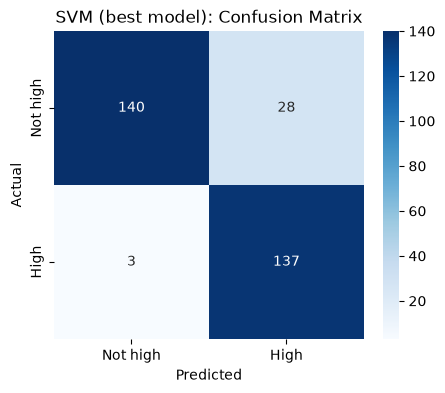

In [4]:
y_pred = grid.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=["Not high", "High"]))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not high", "High"], yticklabels=["Not high", "High"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM (best model): Confusion Matrix")
plt.show()

**How to read these metrics**

- **Accuracy**: share of all test plots classified correctly.
- **Precision (High)**: of the plots predicted "high", how many really are high.
- **Recall (High)**: of the truly high plots, how many the model caught.
- **F1**: the balance of precision and recall.
- **Confusion matrix**: rows are the true class, columns the predicted class. The
  diagonal holds correct predictions; the off-diagonal cells are the two kinds of mistake.

## Visualising the Decision Boundary

The data has 7 features, so it cannot be drawn directly. For visualisation only, the
standardised features are projected onto their first two **principal components**
(Lab 5) and an SVM is trained on those two components. The coloured background shows
which class each region would be assigned to.

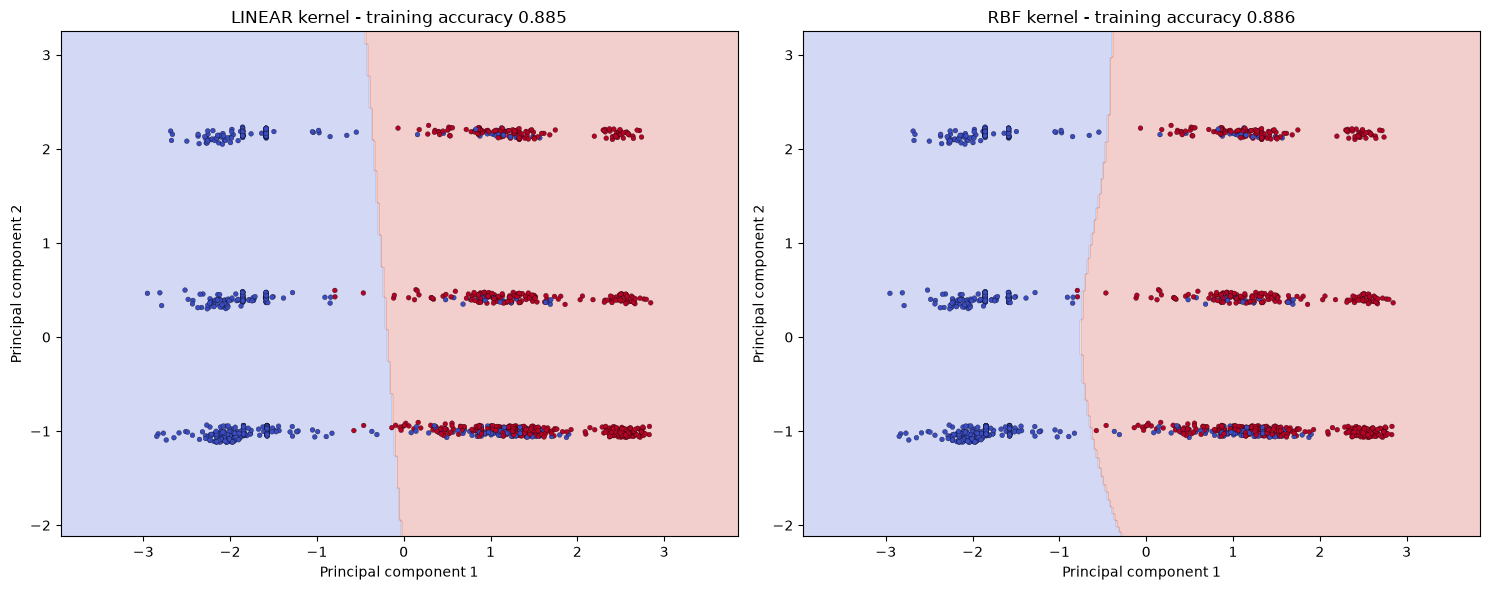

In [5]:
from sklearn.decomposition import PCA

scaler = StandardScaler().fit(X_train)
pca = PCA(n_components=2).fit(scaler.transform(X_train))
P_train = pca.transform(scaler.transform(X_train))

xx, yy = np.meshgrid(np.linspace(P_train[:, 0].min() - 1, P_train[:, 0].max() + 1, 300),
                     np.linspace(P_train[:, 1].min() - 1, P_train[:, 1].max() + 1, 300))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, kernel in zip(axes, ["linear", "rbf"]):
    svm2d = SVC(kernel=kernel, C=1).fit(P_train, y_train)
    zz = svm2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
    ax.scatter(P_train[:, 0], P_train[:, 1], c=y_train, cmap="coolwarm", s=12, edgecolor="k", linewidth=0.2)
    ax.set_title(f"{kernel.upper()} kernel - training accuracy {svm2d.score(P_train, y_train):.3f}")
    ax.set_xlabel("Principal component 1")
    ax.set_ylabel("Principal component 2")
plt.tight_layout()
plt.show()

## Conclusion

Support Vector Machines were used to classify plots as high or not-high PMKSY priority.

| Setting | Value |
|---|---|
| Best model (5-fold CV) | RBF kernel, C = 1, gamma = 0.1 |
| Best CV accuracy, RBF / linear | 0.899 / 0.895 |
| Test accuracy | 0.899 |
| Precision / Recall (High) | 0.83 / 0.98 |

**Observations**

1. **Linear vs RBF:** the RBF kernel is only 0.4 percentage points better than the
   linear kernel in cross-validation, so the boundary between high and not-high
   priority is almost a straight line in feature space. The 2-D plots show this: both
   kernels split the PCA projection in a very similar way.
2. **Effect of C:** with C = 0.01 the margin is very wide and 945 of 1,232 training
   plots are support vectors (underfitting, CV 0.880). As C grows the margin narrows,
   the number of support vectors falls to about 290, and training accuracy rises to
   0.917 at C = 100, while CV accuracy peaks at C = 1 (0.899) and then declines: a
   clear sign of overfitting at large C.
3. **Errors:** like the other classifiers, the SVM catches almost every high-priority
   plot (recall 0.98) at the cost of some false alarms (precision 0.83).
4. The 2-D boundary plots use only two principal components, so they are a
   visual aid; the reported accuracy comes from the model trained on all features.
